# Comparaison de modeles Learning-to-Rank pour les recommandations

**Contexte** : une banque repond au questionnaire de maturite data (32 questions,
6 dimensions) ; le systeme propose des recommandations d'amelioration qu'il faut
**ordonner par priorite**. Ce notebook compare trois paradigmes de Learning-to-Rank
(pointwise, pairwise, listwise), tous batis sur du gradient boosting pour isoler
l'effet du paradigme, plus une regle heuristique de reference (baseline).

Le jeu de donnees (`ltr_dataset.csv` + `ltr_dataset.group`) est synthetique,
genere par `generate_ltr_dataset.py` a partir du meme pipeline de scoring/selection
que l'application (`app.services.scoring`), avec un label de pertinence (`relevance`,
0 a 4) derive d'un oracle latent **jamais expose comme feature**.


In [1]:
# Imports et configuration
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import ndcg_score, average_precision_score

# Reutiliser l'ordre canonique des features defini dans le backend -- ne pas
# le recoder en dur ici.
sys.path.insert(0, str(Path("..").resolve()))
from app.services.features import FEATURE_COLUMNS

SEED = 42
np.random.seed(SEED)

CATEGORY_COL = "category_id"
DATA_PATH = Path("ltr_dataset.csv")
GROUP_PATH = Path("ltr_dataset.group")

print(f"{len(FEATURE_COLUMNS)} features (ordre canonique) : {FEATURE_COLUMNS}")


11 features (ordre canonique) : ['current_level', 'gap_to_max', 'question_global_weight', 'dimension_weight', 'dimension_score', 'global_score', 'regulatory_flag', 'effort', 'dimension_is_weakest', 'na_rate_dimension', 'category_id']


## a. Chargement des donnees

On lit `ltr_dataset.csv` et on **reconstitue les groupes depuis la colonne
`assessment_id`** (pas seulement depuis le fichier `.group`, qui ne sert qu'a
la verification croisee ci-dessous).

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape :", df.shape)
display(df.head())

# Un groupe = les lignes d'un meme assessment_id, dans l'ordre d'apparition
# (le dataset est deja trie par assessment_id -- on ne le re-trie pas, un tri
# aurait pu deplacer les groupes et casser la correspondance avec .group).
group_sizes_from_ids = df.groupby("assessment_id", sort=False).size().to_numpy()

group_sizes_from_file = np.loadtxt(GROUP_PATH, dtype=int)
assert np.array_equal(group_sizes_from_ids, group_sizes_from_file), (
    "Les tailles de groupe recalculees depuis assessment_id ne correspondent "
    "pas au fichier .group -- le dataset n'est probablement plus trie par groupe."
)
print(
    f"{len(group_sizes_from_ids)} groupes (evaluations), "
    f"{group_sizes_from_ids.sum()} lignes -- coherent avec ltr_dataset.group."
)


Shape : (15825, 16)


,assessment_id,reco_code,question_id,dimension_id,current_level,gap_to_max,question_global_weight,dimension_weight,dimension_score,global_score,regulatory_flag,effort,dimension_is_weakest,na_rate_dimension,category_id,relevance
0,1,D1Q1-3,51,13,3,2,3.750000,15.0,2.250000,3.364643,0,2,1,0.0,0,3
1,1,D1Q2-2,52,13,2,3,3.750000,15.0,2.250000,3.364643,0,2,1,0.0,0,4
2,1,D1Q3-2,53,13,2,3,3.750000,15.0,2.250000,3.364643,0,2,1,0.0,0,3
3,1,D1Q4-2,54,13,2,3,3.750000,15.0,2.250000,3.364643,0,2,1,0.0,1,4
4,1,D2Q1-4,55,14,4,1,2.857143,20.0,4.142857,3.364643,0,2,0,0.0,1,1


600 groupes (evaluations), 15825 lignes -- coherent avec ltr_dataset.group.


## b. Decoupage train / validation / test **par groupe**

Le decoupage se fait sur les `assessment_id` (les groupes), jamais sur les
lignes individuelles : mettre deux lignes du meme groupe dans deux jeux
differents serait une fuite de donnees (le modele verrait indirectement des
candidats du meme assessment qu'il doit evaluer). On utilise
`GroupShuffleSplit` a deux niveaux : 70 % train / 30 % temporaire, puis le
temporaire est coupe en 15 % validation / 15 % test.

In [3]:
gss_train = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(gss_train.split(df, groups=df["assessment_id"]))

df_train = df.iloc[train_idx].sort_values("assessment_id").reset_index(drop=True)
df_temp = df.iloc[temp_idx].sort_values("assessment_id").reset_index(drop=True)

gss_val_test = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss_val_test.split(df_temp, groups=df_temp["assessment_id"]))

df_val = df_temp.iloc[val_idx].sort_values("assessment_id").reset_index(drop=True)
df_test = df_temp.iloc[test_idx].sort_values("assessment_id").reset_index(drop=True)

# --- Controle de non-fuite : aucun assessment_id partage entre les 3 jeux ---
ids_train = set(df_train["assessment_id"])
ids_val = set(df_val["assessment_id"])
ids_test = set(df_test["assessment_id"])

assert not (ids_train & ids_val), "Fuite : assessment_id partage train/val"
assert not (ids_train & ids_test), "Fuite : assessment_id partage train/test"
assert not (ids_val & ids_test), "Fuite : assessment_id partage val/test"

n_groups = df["assessment_id"].nunique()
print("Controle de non-fuite : OK, aucun assessment_id partage entre les 3 jeux.\\n")
print(f"Groupes -- train: {len(ids_train)} ({len(ids_train)/n_groups:.1%})  "
      f"val: {len(ids_val)} ({len(ids_val)/n_groups:.1%})  "
      f"test: {len(ids_test)} ({len(ids_test)/n_groups:.1%})")
print(f"Lignes  -- train: {len(df_train)}  val: {len(df_val)}  test: {len(df_test)}")


Controle de non-fuite : OK, aucun assessment_id partage entre les 3 jeux.\n
Groupes -- train: 420 (70.0%)  val: 90 (15.0%)  test: 90 (15.0%)
Lignes  -- train: 11032  val: 2373  test: 2420


## c. Entrainement des trois modeles LTR

Les trois modeles partagent la meme famille (gradient boosting) pour isoler
l'effet du **paradigme** de ranking, et la meme feature categorielle
`category_id` (8 categories, declaree comme telle dans LightGBM et XGBoost).

In [4]:
def make_group_sizes(frame):
    """Tailles de groupe dans l'ordre du DataFrame (deja trie par assessment_id)."""
    return frame.groupby("assessment_id", sort=False).size().to_numpy()


def to_xy(frame):
    X = frame[FEATURE_COLUMNS].copy()
    X[CATEGORY_COL] = X[CATEGORY_COL].astype("category")
    y = frame["relevance"].to_numpy()
    return X, y


X_train, y_train = to_xy(df_train)
X_val, y_val = to_xy(df_val)
X_test, y_test = to_xy(df_test)

group_train = make_group_sizes(df_train)
group_val = make_group_sizes(df_val)
group_test = make_group_sizes(df_test)


In [5]:
# --- Modele POINTWISE : regression sur la pertinence, tri par score predit ---
model_pointwise = lgb.LGBMRegressor(
    objective="regression",
    random_state=SEED,
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    verbosity=-1,
)
model_pointwise.fit(
    X_train, y_train,
    eval_X=X_val, eval_y=y_val,
    eval_metric="rmse",
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
print(f"Pointwise -- meilleure iteration : {model_pointwise.best_iteration_}")


Pointwise -- meilleure iteration : 121


In [6]:
# --- Modele PAIRWISE : XGBoost, objective=rank:pairwise, groupes via DMatrix ---
dtrain = xgb.DMatrix(X_train, label=y_train, enable_categorical=True)
dtrain.set_group(group_train)
dval = xgb.DMatrix(X_val, label=y_val, enable_categorical=True)
dval.set_group(group_val)
dtest = xgb.DMatrix(X_test, label=y_test, enable_categorical=True)
dtest.set_group(group_test)

params_pairwise = {
    "objective": "rank:pairwise",
    "eta": 0.05,
    "max_depth": 6,
    "seed": SEED,
    "tree_method": "hist",
}
model_pairwise = xgb.train(
    params_pairwise,
    dtrain,
    num_boost_round=500,
    evals=[(dtrain, "train"), (dval, "val")],
    early_stopping_rounds=50,
    verbose_eval=False,
)
print(f"Pairwise -- meilleure iteration : {model_pairwise.best_iteration}")


Pairwise -- meilleure iteration : 94


In [7]:
# --- Modele LISTWISE : LightGBM LambdaMART (objective=lambdarank) ---
model_listwise = lgb.LGBMRanker(
    objective="lambdarank",
    random_state=SEED,
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    verbosity=-1,
)
model_listwise.fit(
    X_train, y_train,
    group=group_train,
    eval_X=X_val, eval_y=y_val,
    eval_group=[group_val],
    eval_at=[3, 5, 10],
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
print(f"Listwise -- meilleure iteration : {model_listwise.best_iteration_}")


Listwise -- meilleure iteration : 91


## d. Baseline heuristique (non apprise)

Regle de bon sens a battre : prioriser les questions ou l'ecart au niveau
maximal est grand ET qui pesent lourd dans le score global
(`question_global_weight * gap_to_max`), sans aucun apprentissage.

In [8]:
df_test = df_test.copy()
df_test["score_baseline"] = (
    df_test["question_global_weight"] * df_test["gap_to_max"]
)


## e. Evaluation sur le jeu de test

Metriques de ranking calculees **par groupe puis moyennees** : NDCG@3, NDCG@5,
NDCG@10, et MAP. Le MAP etant une metrique a pertinence binaire, on considere
qu'une recommandation est "pertinente" si `relevance >= 3` (les deux echelons
superieurs sur 0..4) -- un choix de seuil raisonnable, pas une verite unique.

In [9]:
def ndcg_per_group(df_scored, score_col, k):
    scores = []
    for _, g in df_scored.groupby("assessment_id", sort=False):
        if len(g) < 2:
            continue  # NDCG non informatif sur un groupe a 1 element
        y_true = g["relevance"].to_numpy().reshape(1, -1)
        y_score = g[score_col].to_numpy().reshape(1, -1)
        scores.append(ndcg_score(y_true, y_score, k=k))
    return float(np.mean(scores))


def map_per_group(df_scored, score_col, relevance_threshold=3):
    scores = []
    for _, g in df_scored.groupby("assessment_id", sort=False):
        y_true_bin = (g["relevance"] >= relevance_threshold).astype(int).to_numpy()
        if y_true_bin.sum() == 0:
            continue  # AP non definie sans aucun positif dans le groupe
        y_score = g[score_col].to_numpy()
        scores.append(average_precision_score(y_true_bin, y_score))
    return float(np.mean(scores))


def evaluate(df_scored, score_col):
    return {
        "NDCG@3": ndcg_per_group(df_scored, score_col, k=3),
        "NDCG@5": ndcg_per_group(df_scored, score_col, k=5),
        "NDCG@10": ndcg_per_group(df_scored, score_col, k=10),
        "MAP": map_per_group(df_scored, score_col),
    }


In [10]:
df_test["score_pointwise"] = model_pointwise.predict(X_test)
df_test["score_pairwise"] = model_pairwise.predict(dtest)
df_test["score_listwise"] = model_listwise.predict(X_test)

results = {
    "Baseline (heuristique)": evaluate(df_test, "score_baseline"),
    "Pointwise (LGBM regressor)": evaluate(df_test, "score_pointwise"),
    "Pairwise (XGBoost rank:pairwise)": evaluate(df_test, "score_pairwise"),
    "Listwise (LGBM LambdaMART)": evaluate(df_test, "score_listwise"),
}

comparison = pd.DataFrame(results).T
comparison = comparison[["NDCG@3", "NDCG@5", "NDCG@10", "MAP"]]
display(comparison.style.format("{:.4f}").background_gradient(cmap="Greens"))


,NDCG@3,NDCG@5,NDCG@10,MAP
Baseline (heuristique),0.8427,0.8513,0.8631,0.7164
Pointwise (LGBM regressor),0.9739,0.9794,0.9794,0.9664
Pairwise (XGBoost rank:pairwise),0.9752,0.9780,0.9789,0.9649
Listwise (LGBM LambdaMART),0.9723,0.9811,0.9790,0.9641


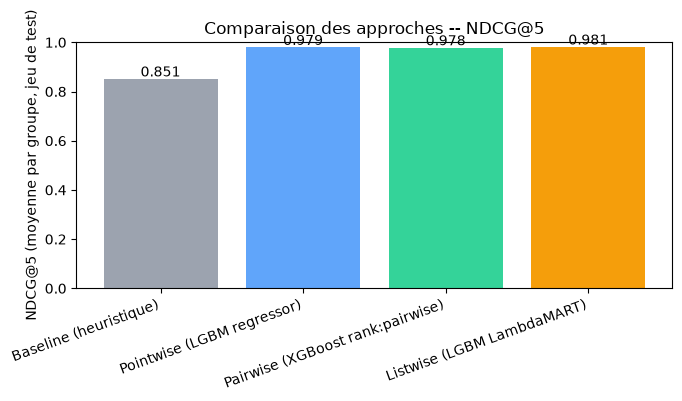

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(comparison.index, comparison["NDCG@5"], color=["#9ca3af", "#60a5fa", "#34d399", "#f59e0b"])
ax.set_ylabel("NDCG@5 (moyenne par groupe, jeu de test)")
ax.set_title("Comparaison des approches -- NDCG@5")
ax.set_ylim(0, 1)
plt.xticks(rotation=20, ha="right")
for bar, value in zip(bars, comparison["NDCG@5"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.3f}", ha="center")
plt.tight_layout()
plt.show()


## Modele gagnant : importance des features et SHAP

Le modele gagnant est celui qui maximise NDCG@5 sur le jeu de test.

In [12]:
learned_models = {
    "Pointwise (LGBM regressor)": model_pointwise,
    "Pairwise (XGBoost rank:pairwise)": model_pairwise,
    "Listwise (LGBM LambdaMART)": model_listwise,
}
learned_comparison = comparison.drop("Baseline (heuristique)")
winner_name = learned_comparison["NDCG@5"].idxmax()
winner_model = learned_models[winner_name]
print(f"Modele gagnant (NDCG@5 le plus eleve parmi les modeles appris) : {winner_name}")


Modele gagnant (NDCG@5 le plus eleve parmi les modeles appris) : Listwise (LGBM LambdaMART)


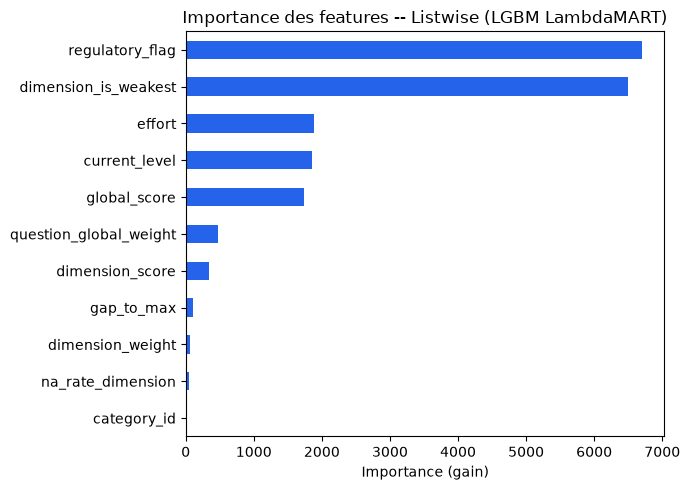

In [13]:
if winner_name == "Pairwise (XGBoost rank:pairwise)":
    importances = pd.Series(
        winner_model.get_score(importance_type="gain"), name="importance"
    )
    importances.index = [FEATURE_COLUMNS[int(f[1:])] for f in importances.index]
else:
    importances = pd.Series(
        winner_model.booster_.feature_importance(importance_type="gain"),
        index=FEATURE_COLUMNS,
        name="importance",
    )

importances = importances.sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(7, 5))
importances.plot.barh(ax=ax, color="#2563eb")
ax.set_title(f"Importance des features -- {winner_name}")
ax.set_xlabel("Importance (gain)")
plt.tight_layout()
plt.show()


C:\Users\USER\AppData\Local\Temp\ipykernel_20540\3672902537.py:16: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, sample, show=False)


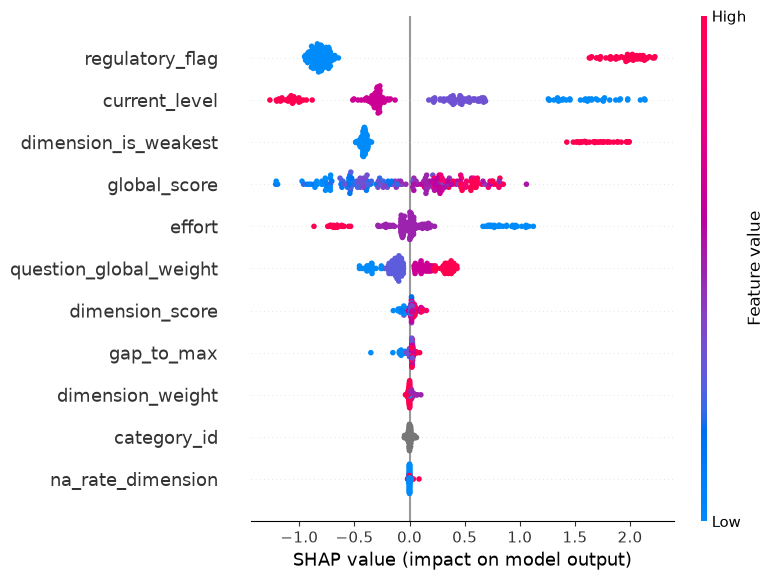

In [14]:
# Resume SHAP (optionnel) -- explique la contribution de chaque feature aux
# scores predits par le modele gagnant, sur un echantillon du jeu de test.
try:
    import shap

    sample = X_test.sample(min(200, len(X_test)), random_state=SEED)
    if winner_name == "Pairwise (XGBoost rank:pairwise)":
        explainer = shap.TreeExplainer(winner_model)
        sample_dmatrix = xgb.DMatrix(sample, enable_categorical=True)
        shap_values = explainer.shap_values(sample_dmatrix)
    else:
        booster = winner_model.booster_
        explainer = shap.TreeExplainer(booster)
        shap_values = explainer.shap_values(sample)

    shap.summary_plot(shap_values, sample, show=False)
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print(f"Resume SHAP indisponible ({type(exc).__name__}: {exc}) -- etape optionnelle, ignoree.")


## g. Pourquoi le NDCG est (volontairement) inferieur a 1

Le label `relevance` provient d'un **oracle latent bruite** (bruit gaussien
ajoute avant la conversion en rang), pas d'une regle deterministe parfaitement
apprenable. Un NDCG proche de 1 signifierait que le modele a memorise le bruit
plutot qu'appris un signal generalisable -- ce qui serait le signe d'un
surapprentissage sur les particularites du jeu synthetique, pas d'un bon
modele. Un NDCG nettement superieur au baseline mais **inferieur a 1** est
donc le resultat attendu et recherche ici.

In [15]:
baseline_ndcg5 = comparison.loc["Baseline (heuristique)", "NDCG@5"]
winner_ndcg5 = comparison.loc[winner_name, "NDCG@5"]

print("=== Conclusion ===")
print(comparison.to_string(float_format=lambda v: f"{v:.4f}"))
print()
print(f"Modele gagnant : {winner_name}")
print(f"NDCG@5 gagnant  : {winner_ndcg5:.4f}")
print(f"NDCG@5 baseline : {baseline_ndcg5:.4f}")
print(f"NDCG@5 < 1 (attendu, labels synthetiques bruites) : {winner_ndcg5 < 1.0}")

assert winner_ndcg5 > baseline_ndcg5, "Le modele gagnant ne bat pas le baseline !"
print("Le modele gagnant bat bien le baseline heuristique.")


=== Conclusion ===
                                  NDCG@3  NDCG@5  NDCG@10    MAP
Baseline (heuristique)            0.8427  0.8513   0.8631 0.7164
Pointwise (LGBM regressor)        0.9739  0.9794   0.9794 0.9664
Pairwise (XGBoost rank:pairwise)  0.9752  0.9780   0.9789 0.9649
Listwise (LGBM LambdaMART)        0.9723  0.9811   0.9790 0.9641

Modele gagnant : Listwise (LGBM LambdaMART)
NDCG@5 gagnant  : 0.9811
NDCG@5 baseline : 0.8513
NDCG@5 < 1 (attendu, labels synthetiques bruites) : True
Le modele gagnant bat bien le baseline heuristique.


**Conclusion.** Voir la cellule ci-dessus pour la designation exacte du
modele gagnant et ses metriques : il s'agit du modele appris qui maximise le
NDCG@5 sur le jeu de test parmi les trois paradigmes compares, et il bat le
baseline heuristique non appris. C'est ce modele (meme famille et memes
hyperparametres) qui est reentraine sur train+validation dans
`train_model.py` pour la mise en production.